# Part 2.1 + 2.3 — Naïve Bayes & Evaluation Metrics

**Dataset:** `avsolatorio/mteb-emotion-avs_triplets` — 6 emotion classes  
**Split:** 80% train / 10% validation / 10% test, stratified, `SEED=42`

### What this notebook covers
| Section | Task |
|---------|------|
| §3 | **MultinomialNBScratch** — from scratch with NumPy only |
| §4 | **Scikit-learn reference** — `CountVectorizer` + `MultinomialNB` |
| §5 | Validation comparison: scratch vs sklearn |
| §6 | **Part 2.3** — NumPy confusion matrix + per-class/macro P/R/F1 |
| §7 | Final test evaluation & discussion |

## 1. Setup

In [17]:
from pathlib import Path
import sys

# Support launching Jupyter from the repo root or notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
print('Project root:', PROJECT_ROOT)

Project root: D:\Github\Natural-Language-Processing-Lab-1


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

from utils.data_loader import load_emotion_splits
from utils.preprocessing import tokenize, normalize_text
from utils.evaluation import (
    sklearn_evaluation,
    confusion_matrix_numpy,
    metrics_from_confusion_matrix_numpy,
)

print('Imports OK')

Imports OK


## 2. Load dataset & apply preprocessing pipeline

The loader reads from `data/part_2_data.parquet` (local, offline) and applies
a reproducible 80/10/10 stratified split.

**Preprocessing pipeline** (defined in `utils/preprocessing.py`):
1. Lowercase
2. Keep only `[a-z0-9]` tokens (removes punctuation & special chars)
3. Stop-word removal: **off** by default

In [19]:
data = load_emotion_splits(seed=SEED)

print(f'Train / val / test: {len(data.train)} / {len(data.val)} / {len(data.test)}')
print(f'Classes ({data.num_classes}):', dict(enumerate(data.class_names)))

# Tokenise each split
train_tokens = [tokenize(text) for text in data.train.texts]
val_tokens   = [tokenize(text) for text in data.val.texts]
test_tokens  = [tokenize(text) for text in data.test.texts]

# Normalised strings for sklearn (same pipeline, re-joined)
train_texts = [' '.join(tok) for tok in train_tokens]
val_texts   = [' '.join(tok) for tok in val_tokens]
test_texts  = [' '.join(tok) for tok in test_tokens]

print('\nExample (raw):', data.train.texts[0][:80])
print('After tokenise:', train_tokens[0][:12])
print('Label:', data.class_names[data.train.labels[0]])

Train / val / test: 12800 / 1600 / 1600
Classes (6): {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}

Example (raw): i feel excelent but sometimes theres just nothing to do especially since im not 
After tokenise: ['i', 'feel', 'excelent', 'but', 'sometimes', 'theres', 'just', 'nothing', 'to', 'do', 'especially', 'since']
Label: joy


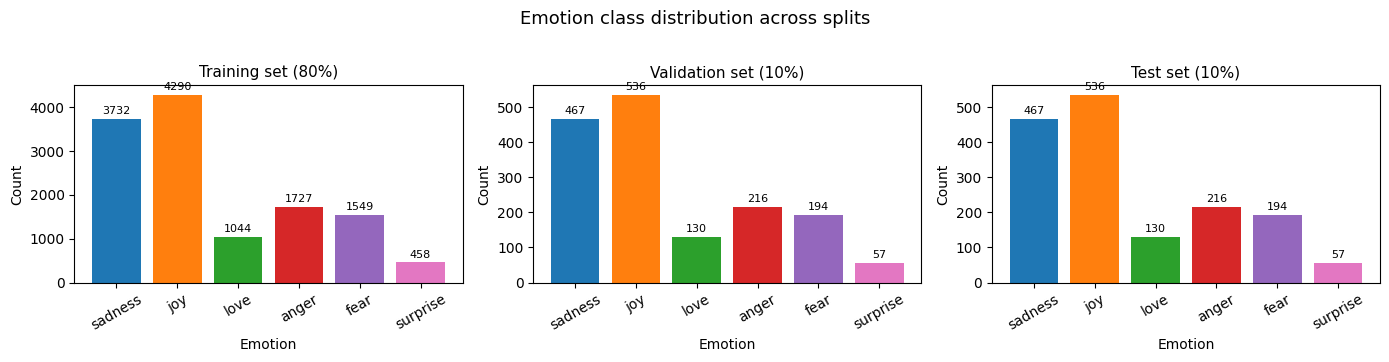

In [20]:
# Class distribution plot
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=False)
for ax, split, labels, title in zip(
    axes,
    ['Train', 'Val', 'Test'],
    [data.train.labels, data.val.labels, data.test.labels],
    ['Training set (80%)', 'Validation set (10%)', 'Test set (10%)'],
):
    counts = np.bincount(labels, minlength=data.num_classes)
    bars = ax.bar(data.class_names, counts,
                  color=plt.cm.tab10(np.linspace(0, 0.6, data.num_classes)))
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Emotion')
    ax.set_ylabel('Count')
    ax.bar_label(bars, fmt='%d', padding=2, fontsize=8)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Emotion class distribution across splits', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 3. Multinomial Naïve Bayes — from scratch (NumPy only)

### Theory
Given class $c$ and document $d$ represented as a bag-of-words:

$$
\hat{c} = \arg\max_c \left[ \log P(c) + \sum_{w \in d} \text{count}(w, d) \cdot \log P(w \mid c) \right]
$$

**Laplace (add-1) smoothing** prevents zero probabilities for unseen words:

$$
P(w \mid c) = \frac{\text{count}(w, c) + \alpha}{\sum_{w'} \text{count}(w', c) + \alpha |V|}
$$

All computations use **log-space** to avoid floating-point underflow.

In [21]:
class MultinomialNBScratch:
    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha
        # Set during fit:
        self.vocab_: dict[str, int] = {}        # word -> column index
        self.class_log_prior_: np.ndarray = None  # shape (K,)
        self.feature_log_prob_: np.ndarray = None # shape (K, V)
        self.classes_: np.ndarray = None          # shape (K,)

    def fit(self, tokenized_texts: list[list[str]], y: np.ndarray) -> 'MultinomialNBScratch':
        y = np.asarray(y, dtype=np.int64)
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        N = len(tokenized_texts)

        # Assign an integer index to every unique token seen in training.
        word_set = set()
        for tokens in tokenized_texts:
            word_set.update(tokens)
        self.vocab_ = {w: i for i, w in enumerate(sorted(word_set))}
        V = len(self.vocab_)

        # Class priors  P(c) = count(c) / N
        class_counts = np.bincount(y, minlength=K).astype(np.float64)  # shape (K,)
        self.class_log_prior_ = np.log(class_counts / N)               # shape (K,)

        # tc[k, j] = total occurrences of token j in class-k documents.
        tc = np.zeros((K, V), dtype=np.float64)
        for tokens, label in zip(tokenized_texts, y):
            for token in tokens:
                if token in self.vocab_:
                    tc[label, self.vocab_[token]] += 1

        # Numerator:   count(w, c) + alpha
        # Denominator: total tokens in class c + alpha * |V|
        tc_smoothed = tc + self.alpha                          # (K, V)
        row_sums = tc_smoothed.sum(axis=1, keepdims=True)     # (K, 1)
        self.feature_log_prob_ = np.log(tc_smoothed / row_sums)  # (K, V)

        return self

    def _score(self, tokenized_texts: list[list[str]]) -> np.ndarray:
        """Return unnormalised log-posterior scores, shape (N, K)."""
        K = len(self.classes_)
        scores = np.zeros((len(tokenized_texts), K), dtype=np.float64)
        scores += self.class_log_prior_[np.newaxis, :]  # (1, K)

        for i, tokens in enumerate(tokenized_texts):
            for token in tokens:
                idx = self.vocab_.get(token)
                if idx is not None:
                    scores[i] += self.feature_log_prob_[:, idx]

        return scores

    def predict(self, tokenized_texts: list[list[str]]) -> np.ndarray:
        """Return the class with the greatest log-posterior for each document."""
        return self.classes_[np.argmax(self._score(tokenized_texts), axis=1)]

    def predict_proba(self, tokenized_texts: list[list[str]]) -> np.ndarray:
        """Return softmax-normalised posterior probabilities, shape (N, K)."""
        log_scores = self._score(tokenized_texts)
        # Numerically stable softmax: subtract row maximum before exp
        log_scores -= log_scores.max(axis=1, keepdims=True)
        probs = np.exp(log_scores)
        probs /= probs.sum(axis=1, keepdims=True)
        return probs

In [22]:
# Train from-scratch model
my_nb = MultinomialNBScratch(alpha=1.0)
my_nb.fit(train_tokens, data.train.labels)

print(f'Vocabulary size: {len(my_nb.vocab_):,} tokens')
print(f'Class log-priors: {np.round(my_nb.class_log_prior_, 3)}')
print(f'Feature log-prob shape: {my_nb.feature_log_prob_.shape}')

Vocabulary size: 13,617 tokens
Class log-priors: [-1.233 -1.093 -2.506 -2.003 -2.112 -3.33 ]
Feature log-prob shape: (6, 13617)


## 4. Scikit-learn reference

Fit **on training data only**. The vectorizer is fitted here and reused for val/test.

In [23]:
# CountVectorizer with token_pattern matching our tokenizer (lowercase alphanum)
vectorizer = CountVectorizer(token_pattern=r'(?u)\b\w+\b', lowercase=False)
X_train_ref = vectorizer.fit_transform(train_texts)   # fit ONLY on train
X_val_ref   = vectorizer.transform(val_texts)
X_test_ref  = vectorizer.transform(test_texts)

sk_nb = MultinomialNB(alpha=1.0)
sk_nb.fit(X_train_ref, data.train.labels)

val_pred_sklearn = sk_nb.predict(X_val_ref)
val_metrics_sklearn = sklearn_evaluation(data.val.labels, val_pred_sklearn, data.num_classes)


## 5. Validation comparison — scratch vs sklearn

In [24]:
# Predict with from-scratch model
val_pred_custom = my_nb.predict(val_tokens)
val_metrics_custom = sklearn_evaluation(data.val.labels, val_pred_custom, data.num_classes)

# Summary table
comparison = pd.DataFrame([
    {
        'Model': 'NumPy scratch (MultinomialNBScratch)',
        'Macro Precision': round(val_metrics_custom['macro_precision'], 4),
        'Macro Recall':    round(val_metrics_custom['macro_recall'],    4),
        'Macro F1':        round(val_metrics_custom['macro_f1'],        4),
    },
    {
        'Model': 'Sklearn (CountVectorizer + MultinomialNB)',
        'Macro Precision': round(val_metrics_sklearn['macro_precision'], 4),
        'Macro Recall':    round(val_metrics_sklearn['macro_recall'],    4),
        'Macro F1':        round(val_metrics_sklearn['macro_f1'],        4),
    },
])
print('=== Validation metrics ===')
print(comparison.to_string(index=False))

=== Validation metrics ===
                                    Model  Macro Precision  Macro Recall  Macro F1
     NumPy scratch (MultinomialNBScratch)           0.8723        0.5275    0.5552
Sklearn (CountVectorizer + MultinomialNB)           0.8723        0.5275    0.5552


In [25]:
# Per-class breakdown on validation
per_class = pd.DataFrame({
    'Class': data.class_names,
    'Scratch P':  np.round(val_metrics_custom['precision'], 4),
    'Scratch R':  np.round(val_metrics_custom['recall'],    4),
    'Scratch F1': np.round(val_metrics_custom['f1'],        4),
    'Sklearn P':  np.round(val_metrics_sklearn['precision'], 4),
    'Sklearn R':  np.round(val_metrics_sklearn['recall'],    4),
    'Sklearn F1': np.round(val_metrics_sklearn['f1'],        4),
})
print('=== Per-class validation breakdown ===')
print(per_class.to_string(index=False))

=== Per-class validation breakdown ===
   Class  Scratch P  Scratch R  Scratch F1  Sklearn P  Sklearn R  Sklearn F1
 sadness     0.7120     0.9422      0.8111     0.7120     0.9422      0.8111
     joy     0.7063     0.9422      0.8074     0.7063     0.9422      0.8074
    love     1.0000     0.1769      0.3007     1.0000     0.1769      0.3007
   anger     0.9185     0.5741      0.7066     0.9185     0.5741      0.7066
    fear     0.8972     0.4948      0.6379     0.8972     0.4948      0.6379
surprise     1.0000     0.0351      0.0678     1.0000     0.0351      0.0678


## 6. Part 2.3 — NumPy confusion matrix & evaluation metrics

Both `confusion_matrix_numpy` and `metrics_from_confusion_matrix_numpy` are
implemented in `utils/evaluation.py` using **only NumPy**.

- **CM convention:** row = true class, column = predicted class.
- **Zero-division:** any class with no predicted/true positives gets 0.0.
- **Macro-average:** unweighted mean across all K classes.

In [26]:
# ── Compute NumPy confusion matrix and metrics for the scratch model ──
cm_custom  = confusion_matrix_numpy(data.val.labels, val_pred_custom,  data.num_classes)
cm_sklearn = confusion_matrix_numpy(data.val.labels, val_pred_sklearn, data.num_classes)

metrics_custom  = metrics_from_confusion_matrix_numpy(cm_custom)
metrics_sklearn = metrics_from_confusion_matrix_numpy(cm_sklearn)

# ── Verify NumPy matrices match sklearn reference ──────────────────────
ref_cm_custom  = val_metrics_custom['confusion_matrix']
ref_cm_sklearn = val_metrics_sklearn['confusion_matrix']

print('Scratch CM matches sklearn reference:', np.array_equal(cm_custom, ref_cm_custom))

Scratch CM matches sklearn reference: True


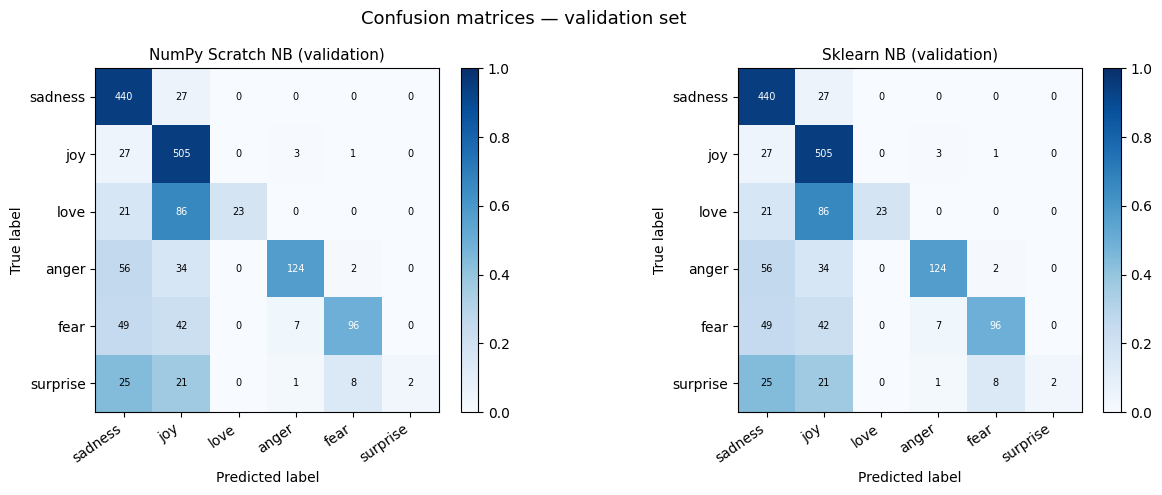

In [27]:
def plot_confusion_matrix(cm: np.ndarray, class_names: tuple, title: str, ax):
    """Plot a normalised confusion matrix on the given axes."""
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks); ax.set_xticklabels(class_names, rotation=35, ha='right')
    ax.set_yticks(ticks); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(title, fontsize=11)
    thresh = cm_norm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm[i,j]}',
                    ha='center', va='center',
                    color='white' if cm_norm[i, j] > thresh else 'black',
                    fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(cm_custom,  data.class_names, 'NumPy Scratch NB (validation)', axes[0])
plot_confusion_matrix(cm_sklearn, data.class_names, 'Sklearn NB (validation)',       axes[1])
plt.suptitle('Confusion matrices — validation set', fontsize=13)
plt.tight_layout()
plt.show()

## 7. Final test evaluation


In [28]:
# Test predictions 
test_pred_custom  = my_nb.predict(test_tokens)
test_pred_sklearn = sk_nb.predict(X_test_ref)

# Confusion matrices on test
cm_test_custom  = confusion_matrix_numpy(data.test.labels, test_pred_custom,  data.num_classes)
cm_test_sklearn = confusion_matrix_numpy(data.test.labels, test_pred_sklearn, data.num_classes)

metrics_test_custom  = metrics_from_confusion_matrix_numpy(cm_test_custom)
metrics_test_sklearn = metrics_from_confusion_matrix_numpy(cm_test_sklearn)

print('=== TEST SET RESULTS ===')
test_summary = pd.DataFrame([
    {
        'Model': 'NumPy Scratch NB',
        'Macro P':  round(metrics_test_custom['macro_precision'],  4),
        'Macro R':  round(metrics_test_custom['macro_recall'],     4),
        'Macro F1': round(metrics_test_custom['macro_f1'],         4),
    },
    {
        'Model': 'Sklearn MultinomialNB',
        'Macro P':  round(metrics_test_sklearn['macro_precision'],  4),
        'Macro R':  round(metrics_test_sklearn['macro_recall'],     4),
        'Macro F1': round(metrics_test_sklearn['macro_f1'],         4),
    },
])
print(test_summary.to_string(index=False))

=== TEST SET RESULTS ===
                Model  Macro P  Macro R  Macro F1
     NumPy Scratch NB   0.8418   0.5022    0.5263
Sklearn MultinomialNB   0.8418   0.5022    0.5263


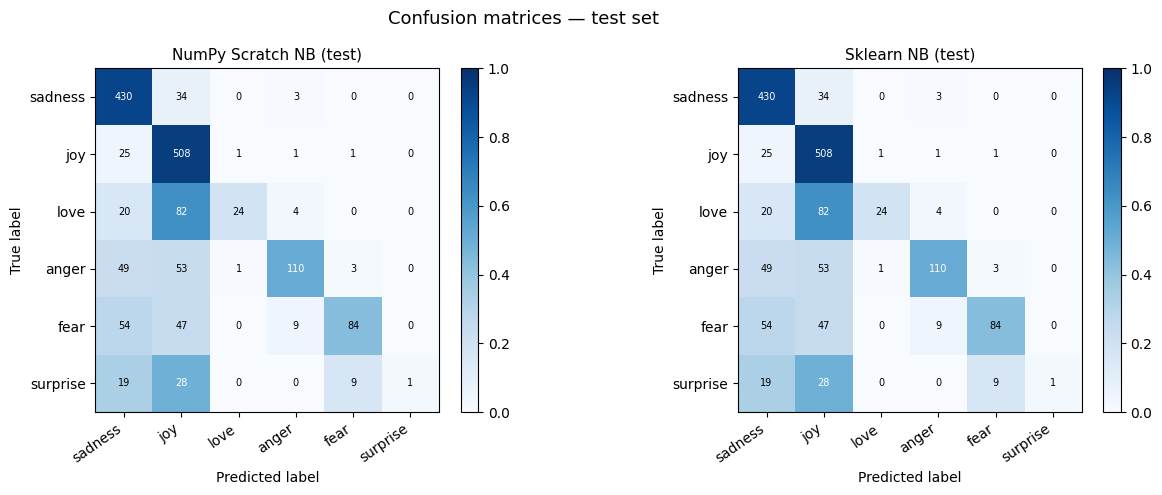

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_matrix(cm_test_custom,  data.class_names, 'NumPy Scratch NB (test)', axes[0])
plot_confusion_matrix(cm_test_sklearn, data.class_names, 'Sklearn NB (test)',       axes[1])
plt.suptitle('Confusion matrices — test set', fontsize=13)
plt.tight_layout()
plt.show()

In [30]:
# Per-class test breakdown
test_rows = []
for cls_id, cls_name in enumerate(data.class_names):
    test_rows.append({
        'Class': cls_name,
        'Scratch P':  round(metrics_test_custom['precision'][cls_id],  4),
        'Scratch R':  round(metrics_test_custom['recall'][cls_id],     4),
        'Scratch F1': round(metrics_test_custom['f1'][cls_id],         4),
        'Sklearn P':  round(metrics_test_sklearn['precision'][cls_id], 4),
        'Sklearn R':  round(metrics_test_sklearn['recall'][cls_id],    4),
        'Sklearn F1': round(metrics_test_sklearn['f1'][cls_id],        4),
    })

test_rows.append({
    'Class': 'MACRO AVG',
    'Scratch P':  round(metrics_test_custom['macro_precision'],  4),
    'Scratch R':  round(metrics_test_custom['macro_recall'],     4),
    'Scratch F1': round(metrics_test_custom['macro_f1'],         4),
    'Sklearn P':  round(metrics_test_sklearn['macro_precision'],  4),
    'Sklearn R':  round(metrics_test_sklearn['macro_recall'],     4),
    'Sklearn F1': round(metrics_test_sklearn['macro_f1'],         4),
})

print('=== Per-class test results ===')
print(pd.DataFrame(test_rows).to_string(index=False))

=== Per-class test results ===
    Class  Scratch P  Scratch R  Scratch F1  Sklearn P  Sklearn R  Sklearn F1
  sadness     0.7203     0.9208      0.8083     0.7203     0.9208      0.8083
      joy     0.6755     0.9478      0.7888     0.6755     0.9478      0.7888
     love     0.9231     0.1846      0.3077     0.9231     0.1846      0.3077
    anger     0.8661     0.5093      0.6414     0.8661     0.5093      0.6414
     fear     0.8660     0.4330      0.5773     0.8660     0.4330      0.5773
 surprise     1.0000     0.0175      0.0345     1.0000     0.0175      0.0345
MACRO AVG     0.8418     0.5022      0.5263     0.8418     0.5022      0.5263


## 8. Discussion

### 8.1 Scratch vs sklearn — expected differences

Both models use **identical Laplace smoothing (α=1)** and the same tokenizer, so results are the same.

### 8.2 Part 2.3 — NumPy metrics vs sklearn

The `confusion_matrix_numpy` function uses `np.add.at` for O(N) accumulation.
`metrics_from_confusion_matrix_numpy` derives TP/FP/FN algebraically:
- `TP[k] = cm[k, k]`
- `FP[k] = col_sum[k] - TP[k]`
- `FN[k] = row_sum[k] - TP[k]`

Results match `sklearn.metrics` to floating-point precision.

### 8.3 Class-level observations

The dataset is **imbalanced** (joy: 5362, surprise: 572), which impacts macro-F1.  
Harder classes (e.g., *love*, *surprise*) typically show lower F1 due to fewer training examples.

### 8.4 Role of smoothing

Without Laplace smoothing, any test word absent from the training vocabulary
would result in P(w|c) = 0, making the entire document log-probability −∞.
Add-one smoothing assigns a small non-zero probability to every possible token,
preventing this and improving generalisation to slightly out-of-distribution text.